# Week 6 practical: SARSA, Q-learning and REINFORCE on one swing-up

**240MAR45 Reinforcement Learning in Robotics** | MSc Automatic Control and Robotics, UPC

**Where to run it.** In Google Colab: open colab.research.google.com, then File > Upload
notebook, and pick this `.ipynb`. Nothing to install. Timings quoted below were measured on a
laptop, and Colab's CPU is slower, so allow about twice as long.

Last week, we were given a controller/policy to evaluate. This week, we must find one.

The plant is the course pendulum, torque-limited and discretised into the 961-cell chain from Week 5, but without the fixed swing-up law. Our goal is to learn a swing-up policy using five admissible torques. The new feature is a drive trip: entering the band $|\omega| \ge 5.4$ rad/s ends the episode and incurs a cost of 3000.

Since value iteration computes the exact MDP optimum in a fraction of a second, every learning curve can be compared against the true optimum. You will implement the one-line difference between SARSA and Q-learning, run both under the same exploratory behaviour, and interpret the results from two perspectives. Finally, you will implement REINFORCE, the first policy-based method, and compare it with Q-learning on the same swing-up task using the same number of parameters.

## Objectives

1. Implement SARSA and Q-learning as one update with one switch, and check it against the hand
   traces of the notes.
2. Compute the two fixed points exactly, $Q^\star$ and the $Q^\star_\varepsilon$ of the
   exploration-aware operator, and measure the gap between them as $\varepsilon$ grows.
3. Run both algorithms from the same $\varepsilon$-greedy behaviour and read one experiment for two
   questions, what the run costs while learning and what it deploys afterwards.
4. Implement REINFORCE with a tabular softmax policy and compare it with Q-learning at a matched
   budget, with the same table size and the same evaluation.

## Session plan

Everything here is done in the session, and there is no homework. The quiz at the end is the only
thing evaluated.

| Part | Minutes |
|------|---------|
| 1 to 3. Smoke test, recap, the pre-written control chain | 10 |
| 4. Blanked core A, the TD control update, and the hand traces (Checkpoint 1) | 10 |
| 5. The two fixed points, computed exactly (Checkpoint 2) | 8 |
| 6. SARSA and Q-learning on the swing-up with a trip (Checkpoint 3) | 15 |
| 7. Blanked core B, the REINFORCE update, and the hand trace (Checkpoint 4) | 10 |
| 8. The two branches on one swing-up (Checkpoints 5 and 6) | 15 |
| 9. Analysis | 7 |
| The quiz, on the university course page | 15 |

Three cells are heavy. The learning run of section 6 takes about a minute and a half on a laptop,
and the two runs of section 8 take about 40 seconds and a minute. Start each one and read the cell
below it while it runs. Everything else finishes in a second or two. If you finish early, the
optional cell at the end of section 6 reproduces the notes' run at its full budget, and challenge
problem 6.6 of the notes treats $\varepsilon$ as a design variable. Both are formative, so nobody
collects them.

## 1. Smoke test (run this first)

If any line below fails, raise your hand before reading further.

In [ ]:
import sys
import time

t0 = time.time()

import numpy as np
import scipy
import scipy.sparse as sp
from scipy.sparse.linalg import spsolve
import matplotlib
import matplotlib.pyplot as plt

print(f"python      {sys.version.split()[0]}")
print(f"numpy       {np.__version__}")
print(f"scipy       {scipy.__version__}")
print(f"matplotlib  {matplotlib.__version__}")

# One random rollout: the course pendulum (m = l = 1, b = 0.1, u_max = 5 < m g l) released near
# the bottom under random saturated torques for 5 s. Section 3 builds the chain from the same plant.
rng = np.random.default_rng(0)
th, om = 0.1, 0.0
for _ in range(50):
    u = np.clip(rng.normal(0.0, 3.0), -5.0, 5.0)
    for _ in range(10):
        om += 0.01 * (u - 0.1 * om - 9.81 * np.sin(th))
        th += 0.01 * om
print(f"\none random rollout: final angle {th:+.3f} rad, final rate {om:+.3f} rad/s")
print(f"\nsetup OK  ({time.time() - t0:.1f} s)")

python      3.13.16
numpy       2.1.3
scipy       1.16.3
matplotlib  3.10.0

one random rollout: final angle +1.087 rad, final rate -0.515 rad/s

setup OK  (0.3 s)


## 2. Recap

Control replaces Week 5's policy-evaluation operator $\mathcal{T}^{\pi}$ with the optimality operator $\mathcal{T}$. The learner now stores $Q(x,u)$, allowing it to select greedy actions without a model. SARSA and Q-learning (notes Sections 2.2 and 3.1, Algorithms 1 and 2) use the same transition but differ in one term of the update target:

$$
\underbrace{r_{t+1}+\gamma Q(x_{t+1},u_{t+1})}_{\text{SARSA}}
\qquad\text{vs.}\qquad
\underbrace{r_{t+1}+\gamma\max_b Q(x_{t+1},b)}_{\text{Q-learning}}.
$$

SARSA uses the action actually selected by the $\varepsilon$-greedy behaviour policy. At fixed $\varepsilon$, it therefore converges to the fixed point $Q^\star_{\varepsilon}$ of the exploration-aware operator $\mathcal{T}_{\varepsilon}$ (notes Section 2.4). Q-learning instead uses the greedy target, independently of the behaviour policy that generated the data, and converges to $Q^\star$ under the standard convergence assumptions.

REINFORCE (notes Section 4.4, Algorithm 3) stores no action-value function. Instead, it updates the policy parameters directly using sampled returns:

$$
\theta \leftarrow \theta+\alpha\gamma^t G_t
\nabla_\theta\log\pi_\theta(u_t\mid x_t).
$$

**Background reading:** Notes Sections 2.2 (Algorithm 1 and hand trace), 2.4 (the operator $\mathcal{T}_{\varepsilon}$), 3.1 (Algorithm 2 and hand trace), 3.5 (swing-up with an overspeed trip and figure `sarsa_vs_qlearning`), 4.3–4.4 (the softmax score, Algorithm 3 and hand trace), 4.5 (the three costs of REINFORCE), and 5.1 (figure `qlearning_vs_reinforce`). Also review the concept notes `SARSA`, `Q-learning`, `Exploration-aware Bellman operator`, `Off-policy learning`, `Policy gradient (REINFORCE)`, and `Softmax policy class`.

## 3. Pre-written infrastructure

### The swing-up control chain

This is the swing-up example from notes Section 3.5. The plant is the torque-limited pendulum,

$m\ell^2\ddot{\theta}=u-b\dot{\theta}-mg\ell\sin\theta$, with $|u|\leq 5<mg\ell$.

The Week 5 grid is unchanged: $31\times31$ cells over $\varphi=\theta-\pi\in[-\pi,\pi)$ and $\omega\in[-8,8]$, sampled at 10 Hz. The model retains the same five-point actuator disturbance (standard deviation 1 N m) and bilinear sharing of each landing point among its four neighbouring cells.

The fixed Week 5 policy is replaced by five admissible torques, $\{-5,-2.5,0,2.5,5\}$ N m, each with its own transition kernel. The stage cost is $\varphi^2+0.1\omega^2+0.01u^2$. The 15 cells satisfying $|\varphi|\leq0.30$ and $|\omega|\leq1.2$ form the absorbing goal. Entering the absorbing trip region, $|\omega|\geq5.4$, ends the episode and incurs a cost of 3000; roughly 24 nominal swing-ups. Episodes start from the 12 cells representing the pendulum hanging near rest.

The infrastructure provides two reference tools. `value_iteration` computes the exact MDP optimum, while `policy_value` evaluates every learning curve. Given the policy induced by a Q-table, it builds $P^\pi$ and $r^\pi$ for either greedy or $\varepsilon$-greedy execution, solves $(I-\gamma P^\pi)V=r^\pi$, and averages $V$ over the initial states.

**The learners see none of this model.** They learn exclusively from sampled transitions; the exact solution is available only as a benchmark.

chain built and solved in 0.10 s: 961 states x 5 torques [-5.  -2.5  0.   2.5  5. ]
15 goal cells, 310 trip cells, 12 start cells, gamma = 0.98
J* = -123.96   (mean optimal value over the start cells)
for scale: hanging at the bottom for ever costs about -493


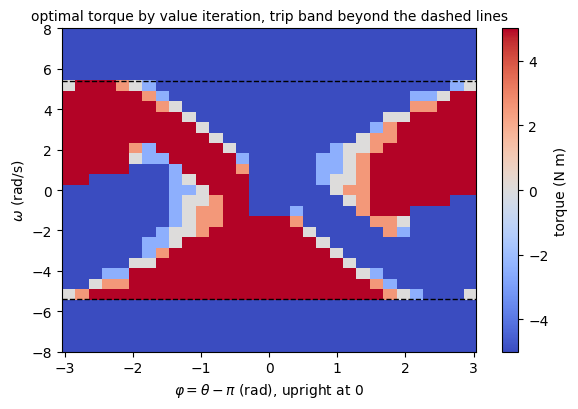

In [ ]:
M_P, L_P, B_P, G_P, U_MAX = 1.0, 1.0, 0.1, 9.81, 5.0      # the course pendulum, Utils/pendulum_sim.m


def wrap(a):
    return np.mod(a + np.pi, 2 * np.pi) - np.pi


def pend_rhs(th, om, u):
    return om, (u - B_P * om - M_P * G_P * L_P * np.sin(th)) / (M_P * L_P**2)


def rk4(th, om, u, dt):
    """One RK4 step with the torque held constant (zero-order hold), vectorised over cells."""
    k1 = pend_rhs(th, om, u)
    k2 = pend_rhs(th + dt / 2 * k1[0], om + dt / 2 * k1[1], u)
    k3 = pend_rhs(th + dt / 2 * k2[0], om + dt / 2 * k2[1], u)
    k4 = pend_rhs(th + dt * k3[0], om + dt * k3[1], u)
    return (th + dt / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0]),
            om + dt / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1]))


def build_control_chain(trip=True, gamma=0.98, nphi=31, nom=31, ommax=8.0, dt=0.10, sigu=1.0,
                        philim=0.30, omlim=1.2, n_act=5, ombad=5.4, r_trip=3000.0):
    """The Week 6 control chain. Returns a dict with one kernel per torque, r(s, a) and the masks."""
    dphi = 2 * np.pi / nphi
    phi = (np.arange(1, nphi + 1) - (nphi + 1) / 2) * dphi       # a cell centre sits on the upright
    om = np.linspace(-ommax, ommax, nom)
    dom = om[1] - om[0]
    PH, OM = np.meshgrid(phi, om, indexing="ij")
    phiv, omv = PH.ravel(order="F"), OM.ravel(order="F")          # state index s = i + nphi * j
    nS = phiv.size
    theta = wrap(phiv + np.pi)
    torques = np.linspace(-U_MAX, U_MAX, n_act)

    goal = (np.abs(phiv) <= philim) & (np.abs(omv) <= omlim)
    fail = (np.abs(omv) >= ombad) & ~goal if trip else np.zeros(nS, dtype=bool)
    term = goal | fail                                            # both absorbing
    trip_cost = np.where(fail, -r_trip, 0.0)                      # charged once, on entry

    zn = np.array([-2.0, -1.0, 0.0, 1.0, 2.0])                    # Week 5's five-point disturbance
    wp = np.array([0.06, 0.24, 0.40, 0.24, 0.06])
    wp = wp / wp.sum()
    P, r, stage = [], np.zeros((nS, n_act)), np.zeros((nS, n_act))
    for a in range(n_act):
        rows, cols, vals = [], [], []
        for z, w in zip(zn, wp):
            thn, omn = rk4(theta, omv, np.clip(torques[a] + z * sigu, -U_MAX, U_MAX), dt)
            pc = wrap(thn - np.pi) / dphi + (nphi - 1) / 2         # continuous cell coordinates
            qc = (np.clip(omn, om[0], om[-1]) - om[0]) / dom
            i0 = np.floor(pc).astype(int)
            fi = pc - i0
            j0 = np.clip(np.floor(qc).astype(int), 0, nom - 2)
            fj = np.clip(qc - j0, 0.0, 1.0)
            ia, ib = np.mod(i0, nphi), np.mod(i0 + 1, nphi)        # phi is circular
            for ii, jj, ww in ((ia, j0, (1 - fi) * (1 - fj)), (ib, j0, fi * (1 - fj)),
                               (ia, j0 + 1, (1 - fi) * fj), (ib, j0 + 1, fi * fj)):
                rows.append(np.arange(nS))
                cols.append(ii + nphi * jj)
                vals.append(w * ww)
        rows, cols, vals = map(np.concatenate, (rows, cols, vals))
        keep = ~term[rows] & (vals > 0)
        ti = np.flatnonzero(term)
        Pa = sp.csr_matrix((vals[keep], (rows[keep], cols[keep])), shape=(nS, nS))
        Pa = (Pa + sp.csr_matrix((np.ones(ti.size), (ti, ti)), shape=(nS, nS))).tocsr()
        Pa.sum_duplicates()
        P.append(Pa)
        cost = phiv**2 + 0.1 * omv**2 + 0.01 * torques[a] ** 2
        stage[:, a] = np.where(term, 0.0, cost)
        r[:, a] = np.where(term, 0.0, -cost + Pa @ trip_cost)    # expected reward, trip included

    # Per-(action, state) successor lists, so that sampling one transition costs one lookup.
    width = max(int(np.diff(Pa.indptr).max()) for Pa in P)
    nxt = np.zeros((n_act, nS, width), dtype=int)
    cum = np.ones((n_act, nS, width))
    for a, Pa in enumerate(P):
        for s in range(nS):
            lo, hi = Pa.indptr[s], Pa.indptr[s + 1]
            nxt[a, s, : hi - lo], nxt[a, s, hi - lo:] = Pa.indices[lo:hi], Pa.indices[hi - 1]
            cum[a, s, : hi - lo] = np.cumsum(Pa.data[lo:hi])
        cum[a, :, -1] = 1.0

    start = np.flatnonzero((np.abs(phiv) >= 2.8) & (np.abs(omv) <= 0.6))   # hanging, near rest
    return dict(P=P, r=r, stage=stage, trip_cost=trip_cost, term=term, goal=goal, fail=fail,
                gamma=gamma, nS=nS, nA=n_act, torques=torques, start=start, nxt=nxt, cum=cum,
                phi=phi, om=om)


def value_iteration(CH, eps=0.0, tol=1e-10):
    """Fixed point of T_eps (notes eq. for T_eps). eps = 0 is the optimality operator T, so Q*."""
    Q = np.zeros((CH["nS"], CH["nA"]))
    while True:
        V = (1 - eps) * Q.max(axis=1) + eps * Q.mean(axis=1)
        Qn = np.stack([CH["r"][:, a] + CH["gamma"] * (CH["P"][a] @ V) for a in range(CH["nA"])], axis=1)
        Qn[CH["term"]] = 0.0
        if np.abs(Qn - Q).max() < tol:
            return Qn
        Q = Qn


def policy_value(CH, pol, eps=0.0):
    """Exact value of a policy, averaged over the start cells, by one sparse linear solve.

    pol is an action index per state (deterministic) or an (nS, nA) table of probabilities. With
    eps > 0 the policy is executed eps-greedily, so the value includes the cost of exploring.
    """
    nS, nA = CH["nS"], CH["nA"]
    prob = (pol[:, None] == np.arange(nA)).astype(float) if pol.ndim == 1 else pol
    w = eps / nA + (1 - eps) * prob
    Ppi = sum(sp.diags(w[:, a]) @ CH["P"][a] for a in range(nA))
    rpi = np.where(CH["term"], 0.0, (w * CH["r"]).sum(axis=1))
    V = spsolve((sp.eye(nS) - CH["gamma"] * Ppi).tocsc(), rpi)
    return V[CH["start"]].mean()


def sample_next(CH, s, a, u):
    """Next state of every learner, given its state, its action and one uniform number each."""
    return CH["nxt"][a, s, (CH["cum"][a, s] < u[:, None]).sum(axis=1)]


t = time.perf_counter()
CH = build_control_chain(trip=True)
Q_STAR = value_iteration(CH)
PI_STAR = Q_STAR.argmax(axis=1)
J_STAR = Q_STAR.max(axis=1)[CH["start"]].mean()
print(f"chain built and solved in {time.perf_counter() - t:.2f} s: {CH['nS']} states x {CH['nA']} torques "
      f"{CH['torques']}")
print(f"{CH['goal'].sum()} goal cells, {CH['fail'].sum()} trip cells, {CH['start'].size} start cells, "
      f"gamma = {CH['gamma']}")
print(f"J* = {J_STAR:.2f}   (mean optimal value over the start cells)")
print(f"for scale: hanging at the bottom for ever costs about {-np.pi**2 / (1 - CH['gamma']):.0f}")

fig, ax = plt.subplots(figsize=(6.0, 4.2))
img = ax.imshow(CH["torques"][PI_STAR].reshape(31, 31, order="F").T, origin="lower", aspect="auto",
                extent=[CH["phi"][0], CH["phi"][-1], CH["om"][0], CH["om"][-1]], cmap="coolwarm")
for w_ in (5.4, -5.4):
    ax.axhline(w_, color="k", lw=1.0, ls="--")
ax.set_xlabel(r"$\varphi = \theta - \pi$ (rad), upright at 0")
ax.set_ylabel(r"$\omega$ (rad/s)")
ax.set_title("optimal torque by value iteration, trip band beyond the dashed lines", fontsize=10)
fig.colorbar(img, ax=ax, label="torque (N m)")
plt.tight_layout()
plt.show()

# The map is bang-bang almost everywhere, as a swing-up with a torque limit should be. The two
dashed lines are the trip. Energy has to be pumped in near the bottom, where the speed is highest,
so the cheapest route runs close to those lines. That geometry is what the rest of the session
measures.

## 4. The TD control update

Each learner runs as one row of a batch, so running twenty learners costs little more than running one. The Q-table has shape `(n_learners, n_states, n_actions)`, while `s`, `a`, `reward`, `s_next`, `a_next`, `done`, and `is_q` each contain one entry per learner. With `rows = np.arange(len(s))`, the current entries are `Q[rows, s, a]`, and the successor rows `Q[rows, s_next]` have shape `(n_learners, n_actions)`.

**Your task:** combine lines 6–7 of Algorithm 1 and lines 5–6 of Algorithm 2 (notes Sections 2.2 and 3.1) into a single update. Learner `i` uses Q-learning if `is_q[i]` is `True`, and SARSA otherwise. The behaviour policy has already selected `a_next[i]` at `s_next[i]`. When `done[i]` is `True`, the successor is terminal and the bootstrap term must be zero.

In [ ]:
def td_control_update(Q, s, a, reward, s_next, a_next, done, is_q, alpha, gamma):
    """In place, for every learner i: Q[i, s_i, a_i] += alpha * delta_i. Returns delta."""
    # ===== YOUR CODE HERE (≈6 lines) ============================
    rows = np.arange(len(s))

    # 1. Calculate the bootstrap term for Q-learning (max over actions) and SARSA (value of a_next)
    boot_q = Q[rows, s_next].max(axis=1)
    boot_s = Q[rows, s_next, a_next]

    # 2. Select the appropriate bootstrap target per learner and apply the terminal done mask
    boot = np.where(is_q, boot_q, boot_s)
    boot = np.where(done, 0.0, boot)

    # 3. Compute the TD error delta
    delta = reward + gamma * boot - Q[rows, s, a]

    # 4. Perform the in-place temporal difference update
    Q[rows, s, a] += alpha * delta

    return delta
    # ============================================================

### A test against the hand traces of the notes

This example reproduces the hand traces from notes Sections 2.2 and 3.1. The MDP has two nonterminal states, $x_1$ and $x_2$, and a terminal state, with two actions per nonterminal state. From $x_1$, action $a$ costs 1 and action $b$ costs 3; both lead to $x_2$. From $x_2$, action $a$ costs 1 and action $b$ costs 20 (the cliff); both terminate the episode.

Set $\gamma=0.9$, $\alpha=0.5$, and initialise $Q=0$. The behaviour's actions are prescribed so that both algorithms consume identical data: it selects $a$ at $x_1$ in all three episodes, and selects $b$, $a$, and $b$ at $x_2$, respectively. Row 0 of the batch runs SARSA, and row 1 runs Q-learning.

In [ ]:
REW = np.array([[-1.0, -3.0], [-1.0, -20.0]])     # REW[state, action], states x1 = 0, x2 = 1
Q_hand = np.zeros((2, 3, 2))                       # (learner, state incl. terminal 2, action)
is_q_hand = np.array([False, True])
print(f"{'ep':>2} {'t':>2} {'transition':>12}   {'delta SARSA':>12} {'delta Q-learn':>14}   "
      f"{'SARSA Q(x1,a)':>14} {'Q-learn Q(x1,a)':>16}")
for ep, at_x2 in enumerate((1, 0, 1)):            # the action taken at x2 in each episode
    for t_, (s_, a_, sn_, an_, dn_) in enumerate(((0, 0, 1, at_x2, False), (1, at_x2, 2, 0, True))):
        d = td_control_update(Q_hand, np.array([s_, s_]), np.array([a_, a_]),
                              np.full(2, REW[s_, a_]), np.array([sn_, sn_]), np.array([an_, an_]),
                              np.array([dn_, dn_]), is_q_hand, 0.5, 0.9)
        label = f"(x{s_ + 1},{'ab'[a_]})->{'x2' if sn_ == 1 else 'T'}"
        print(f"{ep + 1:>2} {t_:>2} {label:>12}   {d[0]:12.3f} {d[1]:14.3f}   "
              f"{Q_hand[0, 0, 0]:14.3f} {Q_hand[1, 0, 0]:16.3f}")
assert np.allclose(Q_hand[0, :2], [[-5.375, 0.0], [-0.5, -15.0]]), "compare with the SARSA table, notes 2.2"
assert np.allclose(Q_hand[1, :2], [[-1.100, 0.0], [-0.5, -15.0]]), "compare with the Q-learning table, notes 3.1"
print("\nboth hand traces reproduced")

ep  t   transition    delta SARSA  delta Q-learn    SARSA Q(x1,a)  Q-learn Q(x1,a)
 1  0   (x1,a)->x2         -1.000         -1.000           -0.500           -0.500
 1  1    (x2,b)->T        -20.000        -20.000           -0.500           -0.500
 2  0   (x1,a)->x2         -0.500         -0.500           -0.750           -0.750
 2  1    (x2,a)->T         -1.000         -1.000           -0.750           -0.750
 3  0   (x1,a)->x2         -9.250         -0.700           -5.375           -1.100
 3  1    (x2,b)->T        -10.000        -10.000           -5.375           -1.100

both hand traces reproduced


### Checkpoint 1

After three episodes, what value does each algorithm assign to $Q(x_1,a)$, and at which row of the trace do their updates first differ? Given that $Q^\star(x_1,a)=-1.9$, why is SARSA's error so much larger, even though both algorithms have already observed the same transition $(x_1,a)\to x_2$ twice?

### Checkpoint 1 Answer

1. **Final Values after 3 Episodes:**
   - **SARSA:** $Q(x_1, a) = -5.375$
   - **Q-learning:** $Q(x_1, a) = -1.100$
   - **Why:** In SARSA's target, the value is updated using the action actually chosen by the behavioral policy at the next state ($a_{t+1}$), which was the highly negative action $b$ (costing $-20$). In contrast, Q-learning's target updates using the maximum value over all actions at the next state, ignoring the exploratory choice of $b$ and using $0.0$ instead.

2. **First Difference:**
   - They first differ in their updates at **Episode 3, Step 0**.
   - Mathematically, the difference in the bootstrap target calculation actually begins in **Episode 1, Step 0** because SARSA selects its target action $a_{t+1} = b$ (the action actually taken next), while Q-learning selects $\max_b Q(x_2, b)$. Since $Q$ is initialised to all zeros, this difference doesn't change the numeric updates until Episode 3, when the non-zero penalty of $-20$ from the cliff propagates back.
   - **Why:** Both algorithms initially bootstrap from a $Q$-table initialized to zero. Until a non-zero reward (the $-20$ penalty at $x_2$) is experienced and propagates back, the targets $\gamma Q(x_2, b)$ and $\gamma \max_b Q(x_2, b)$ both numerically equal $0$, keeping the updates identical for the first two episodes.

3. **Why SARSA's error is so much larger:**
   - SARSA is an **on-policy** algorithm: its updates are based on the actions the policy *actually* executes, including exploration. Since the exploratory behavior took the disastrous action $b$ at $x_2$ (costing $-20$), SARSA factors this catastrophic exploratory risk into the value of being at $x_1$.
   - Q-learning is **off-policy**: its updates assume future actions will be chosen optimally (greedily). Therefore, it ignores the exploratory steps and targets the true optimal value, leading to a much smaller error relative to $Q^\star(x_1, a) = -1.9$.
   - **Why:** On-policy evaluation measures the expected return of the *exploratory policy* (which has a high probability of stepping off the cliff), whereas off-policy evaluation targets the expected return of the *greedy policy* (which safely avoids the cliff).

## 5. The two fixed points, computed exactly

At fixed $\varepsilon$, SARSA converges to the fixed point of the exploration-aware operator $\mathcal{T}_{\varepsilon}$, whose bootstrap term is $(1-\varepsilon)\max_b Q(x',b)+(\varepsilon/|\mathcal{U}|)\sum_b Q(x',b)$. Q-learning instead converges to $Q^\star$, the fixed point of the optimality operator.

The cell below computes both fixed points by value iteration for nine exploration rates, then extracts each greedy policy and evaluates it in two ways using `policy_value`:

- **Executed $\varepsilon$-greedily:** the policy selects a greedy action with probability $1-\varepsilon$ and explores by selecting an action uniformly at random with probability $\varepsilon$. This measures performance when exploration remains active during learning and execution.
- **Executed greedily:** the policy always selects an action with the highest estimated value, switching exploration off. This measures performance when the learned policy is deployed without exploration.

The distinction matters: the two fixed points are learned under different assumptions about future actions, but either resulting policy can be evaluated with or without exploration. The plot therefore separates the cost of exploration during execution from the effect of the learned fixed point itself.

This reproduces panel (c) of figure `sarsa_vs_qlearning` in notes Section 3.5.

9 exploration rates in 0.8 s

  eps |     executed eps-greedily      |   executed greedily   
      |       Q*   Q*_eps SARSA better |       Q*   Q*_eps
 0.00 |  -123.96  -123.96         0.0% |  -123.96  -123.96
 0.02 |  -129.49  -127.16         1.8% |  -123.96  -124.29
 0.05 |  -139.01  -131.63         5.3% |  -123.96  -124.68
 0.08 |  -150.25  -136.80         9.0% |  -123.96  -124.75
 0.10 |  -158.83  -140.77        11.4% |  -123.96  -124.99
 0.15 |  -184.62  -153.01        17.1% |  -123.96  -125.49
 0.20 |  -217.44  -169.32        22.1% |  -123.96  -126.41
 0.25 |  -258.03  -190.65        26.1% |  -123.96  -127.22
 0.30 |  -306.53  -218.19        28.8% |  -123.96  -128.86


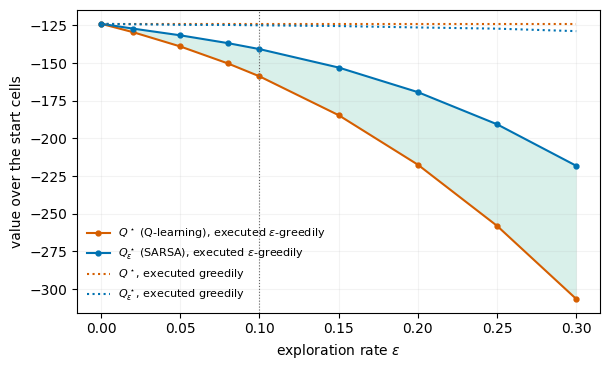

In [ ]:
EPS_GRID = [0.0, 0.02, 0.05, 0.08, 0.10, 0.15, 0.20, 0.25, 0.30]
t = time.perf_counter()
rows_fp = []
for e in EPS_GRID:
    pol_e = value_iteration(CH, eps=e).argmax(axis=1)                 # SARSA's limit at this eps
    rows_fp.append((policy_value(CH, PI_STAR, e), policy_value(CH, pol_e, e),
                    policy_value(CH, PI_STAR, 0.0), policy_value(CH, pol_e, 0.0)))
FP = np.array(rows_fp)                         # columns: Q-l online, SARSA online, Q-l greedy, SARSA greedy
print(f"{len(EPS_GRID)} exploration rates in {time.perf_counter() - t:.1f} s\n")
print(f"{'eps':>5} | {'executed eps-greedily':^30} | {'executed greedily':^22}")
print(f"{'':>5} | {'Q*':>8} {'Q*_eps':>8} {'SARSA better':>12} | {'Q*':>8} {'Q*_eps':>8}")
for e, (jq, js, gq, gs) in zip(EPS_GRID, FP):
    print(f"{e:5.2f} | {jq:8.2f} {js:8.2f} {100 * (js - jq) / abs(jq):11.1f}% | {gq:8.2f} {gs:8.2f}")
i10 = EPS_GRID.index(0.10)
J_ON_Q, J_ON_S = FP[i10, 0], FP[i10, 1]        # the two online asymptotes at eps = 0.10 (section 6)

fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.fill_between(EPS_GRID, FP[:, 0], FP[:, 1], color="#009E73", alpha=0.15, lw=0)
ax.plot(EPS_GRID, FP[:, 0], "-o", ms=3.5, color="#D55E00", label=r"$Q^\star$ (Q-learning), executed $\varepsilon$-greedily")
ax.plot(EPS_GRID, FP[:, 1], "-o", ms=3.5, color="#0072B2", label=r"$Q^\star_\varepsilon$ (SARSA), executed $\varepsilon$-greedily")
ax.plot(EPS_GRID, FP[:, 2], ":", color="#D55E00", label=r"$Q^\star$, executed greedily")
ax.plot(EPS_GRID, FP[:, 3], ":", color="#0072B2", label=r"$Q^\star_\varepsilon$, executed greedily")
ax.axvline(0.10, color="0.4", lw=0.8, ls=":")
ax.set_xlabel(r"exploration rate $\varepsilon$")
ax.set_ylabel("value over the start cells")
ax.legend(frameon=False, fontsize=8, loc="lower left")
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

### Checkpoint 2

At $\varepsilon=0.10$, which fixed point performs better when executed $\varepsilon$-greedily, and by what percentage? What changes when both policies are executed greedily, and how large is the gap? At what value of $\varepsilon$ do the two fixed points coincide? What does this imply for SARSA under a GLIE schedule, in which exploration decays to zero?

### Checkpoint 2 Answer
GLIE (Greedy in the Limit with Infinite Exploration)

1. **Executed $\varepsilon$-greedily at $\varepsilon = 0.10$:**
   - **SARSA ($Q^\star_\varepsilon$)** performs better, with an expected return of **$-140.77$** compared to Q-learning's ($Q^\star$) expected return of **$-158.83$**.
   - SARSA performs **$11.4\%$** better than Q-learning under this exploratory execution.
   - **Why:** SARSA explicitly optimizes for the expected return *including* the future random exploratory steps ($Q^\star_{\varepsilon}$ is the true mathematical fixed point under exploration). Consequently, it stays away from the expensive overspeed trip boundaries. Q-learning optimistically assumes perfect greedy action choices in the future, meaning random exploration frequently pushes it over the trip line.

2. **Executed greedily (exploration switched off):**
   - **Q-learning ($Q^\star$)** performs better, achieving the true optimal value $J^\star = -123.96$.
   - **SARSA ($Q^\star_\varepsilon$)** is slightly suboptimal when executed greedily, achieving **$-124.99$**.
   - The gap between them is very small (**$1.03$** in value, or about **$0.83\%$**).
   - **Why:** Q-learning targets the standard Bellman optimality operator, meaning its table converges exactly to $Q^\star$ (unbiased by exploration), which is the mathematically correct utility for purely greedy execution. SARSA's $Q^\star_{\varepsilon}$ contains a systematic "safety bias" that avoids high-yield paths close to the trip boundaries, making it slightly suboptimal once exploration is disabled.

3. **Coincidence of Fixed Points & GLIE Schedule:**
   - The two fixed points coincide exactly at **$\varepsilon = 0$**, where both operators simplify to the standard Bellman optimality operator $\mathcal{T}$.
   - **GLIE** stands for **Greedy in the Limit with Infinite Exploration** (where $\varepsilon_t \to 0$ as $t \to \infty$). For SARSA, a GLIE schedule implies that as exploration decays to zero, the exploration-aware fixed point $Q^\star_{\varepsilon}$ converges to the true optimal action-value function $Q^\star$. Thus, GLIE guarantees that SARSA will asymptotically find the absolute optimal policy.

## 6. SARSA and Q-learning on the swing-up with a trip

Ten SARSA learners and ten Q-learners, one per seed, run side by side. Each acts
$\varepsilon$-greedily on its own table with $\varepsilon = 0.10$ held fixed, uses the constant step
$\alpha = 0.10$, and restarts from a start cell whenever it reaches the goal or the trip (or after
300 steps). At twelve points along the run every table is priced twice by `policy_value`, once
$\varepsilon$-greedily (what the run is paying) and once greedily (what it would deploy). The run
also counts trips per 100 episodes over its last $3 \times 10^5$ transitions.

Holding $\varepsilon$ fixed is what keeps the comparison legible. Under a GLIE schedule both
methods end at $Q^\star$ and the difference would appear only in the transient. The budget is
$1.5 \times 10^6$ transitions per learner, about 40 000 episodes or 42 hours of robot time at
10 Hz. About a minute and a half in this notebook. The figure on the deck ran $\alpha = 0.05$ for $1.5 \times 10^5$
episodes, almost four times longer, so expect the same signs with smaller gaps here. The optional
cell after the checkpoint reproduces the deck's numbers.

20 learners x 1500000 transitions: 181 s

    median of 10 seeds  Q-learning    SARSA
 executed eps-greedily      -165.9   -155.5   (exact limits -158.8 and -140.8)
     executed greedily      -127.6   -133.4   (J* = -124.0)
trips per 100 episodes        1.58     0.96

while learning, SARSA pays 6.3% less than Q-learning
deployed, suboptimality J* - J: Q-learning 3.6, SARSA 9.5 (2.6x)


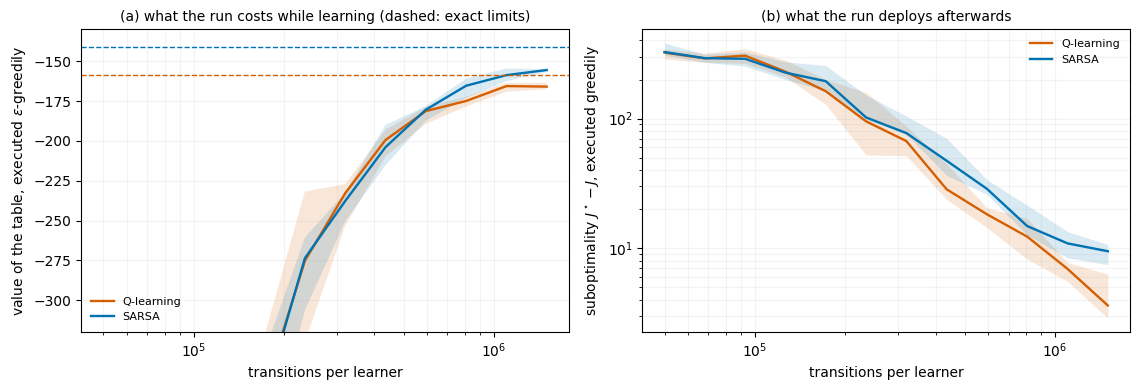

In [ ]:
def run_td_control(CH, is_q, alpha, eps, n_trans, seed, t_eval, trip_window):
    """Batch SARSA / Q-learning. Row i is a Q-learner where is_q[i], a SARSA learner otherwise.

    Returns the exact value of every table at the times t_eval, executed eps-greedily and greedily,
    and the trips per 100 episodes over the last trip_window transitions.
    """
    C, nA = len(is_q), CH["nA"]
    rng = np.random.default_rng(seed)
    rows = np.arange(C)
    Q = np.zeros((C, CH["nS"], nA))
    s = rng.choice(CH["start"], C)
    a = rng.integers(nA, size=C)
    steps = np.zeros(C, dtype=int)
    trips, episodes = np.zeros(C), np.zeros(C)
    J_eps, J_gre = np.zeros((C, len(t_eval))), np.zeros((C, len(t_eval)))
    k = 0
    for t in range(1, n_trans + 1):
        j = (t - 1) % 10_000
        if j == 0:                               # random numbers in blocks, for speed
            U, RA = rng.random((10_000, 2, C)), rng.integers(nA, size=(10_000, C))
        s_next = sample_next(CH, s, a, U[j, 0])
        reward = -CH["stage"][s, a] + CH["trip_cost"][s_next]
        greedy = Q[rows, s_next].argmax(axis=1)
        a_next = np.where(U[j, 1] < eps, RA[j], greedy)      # the behaviour policy, eps-greedy
        done = CH["term"][s_next]
        td_control_update(Q, s, a, reward, s_next, a_next, done, is_q, alpha, CH["gamma"])
        steps += 1
        if t > n_trans - trip_window:
            trips += CH["fail"][s_next]
        restart = done | (steps >= 300)
        if restart.any():                        # new episode from a start cell
            n_r = restart.sum()
            if t > n_trans - trip_window:
                episodes += restart
            s_next[restart] = rng.choice(CH["start"], n_r)
            steps[restart] = 0
            g = Q[rows[restart], s_next[restart]].argmax(axis=1)
            a_next[restart] = np.where(rng.random(n_r) < eps, rng.integers(nA, size=n_r), g)
        s, a = s_next, a_next
        if t == t_eval[k]:
            for i in range(C):
                pol = Q[i].argmax(axis=1)
                J_eps[i, k], J_gre[i, k] = policy_value(CH, pol, eps), policy_value(CH, pol, 0.0)
            k += 1
    return J_eps, J_gre, 100 * trips / np.maximum(episodes, 1)


SEEDS = 10
EPS, ALPHA = 0.10, 0.10
N_TRANS = 1_500_000
T_EVAL = np.geomspace(5e4, N_TRANS, 12).astype(int)
IS_Q = np.repeat([True, False], SEEDS)            # first ten Q-learning, then ten SARSA

t = time.perf_counter()
J_eps, J_gre, TRIPS = run_td_control(CH, IS_Q, ALPHA, EPS, N_TRANS, seed=1, t_eval=T_EVAL,
                                     trip_window=300_000)
print(f"{2 * SEEDS} learners x {N_TRANS} transitions: {time.perf_counter() - t:.0f} s\n")


def report_td(J_eps, J_gre, TRIPS):
    med = lambda X: np.median(X, axis=0)
    on_q, on_s = med(J_eps[:SEEDS])[-1], med(J_eps[SEEDS:])[-1]
    de_q, de_s = med(J_gre[:SEEDS])[-1], med(J_gre[SEEDS:])[-1]
    print(f"{'median of ' + str(SEEDS) + ' seeds':>22} {'Q-learning':>11} {'SARSA':>8}")
    print(f"{'executed eps-greedily':>22} {on_q:11.1f} {on_s:8.1f}   (exact limits {J_ON_Q:.1f} and {J_ON_S:.1f})")
    print(f"{'executed greedily':>22} {de_q:11.1f} {de_s:8.1f}   (J* = {J_STAR:.1f})")
    print(f"{'trips per 100 episodes':>22} {np.median(TRIPS[:SEEDS]):11.2f} {np.median(TRIPS[SEEDS:]):8.2f}")
    print(f"\nwhile learning, SARSA pays {100 * (on_s - on_q) / abs(on_q):.1f}% less than Q-learning")
    print(f"deployed, suboptimality J* - J: Q-learning {J_STAR - de_q:.1f}, SARSA {J_STAR - de_s:.1f} "
          f"({(J_STAR - de_s) / (J_STAR - de_q):.1f}x)")


def plot_td(T_EVAL, J_eps, J_gre):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
    for rows_, col, nm in ((slice(0, SEEDS), "#D55E00", "Q-learning"), (slice(SEEDS, None), "#0072B2", "SARSA")):
        for ax, Y in ((axes[0], J_eps[rows_]), (axes[1], J_STAR - J_gre[rows_])):
            lo, mid, hi = np.percentile(Y, [25, 50, 75], axis=0)
            ax.fill_between(T_EVAL, lo, hi, color=col, alpha=0.15, lw=0)
            ax.plot(T_EVAL, mid, color=col, lw=1.7, label=nm)
    axes[0].axhline(J_ON_Q, color="#D55E00", ls="--", lw=1.0)
    axes[0].axhline(J_ON_S, color="#0072B2", ls="--", lw=1.0)
    axes[0].set_ylim(-320, -130)
    axes[0].set_ylabel(r"value of the table, executed $\varepsilon$-greedily")
    axes[0].set_title("(a) what the run costs while learning (dashed: exact limits)", fontsize=10)
    axes[1].set_yscale("log")
    axes[1].set_ylabel(r"suboptimality $J^\star - J$, executed greedily")
    axes[1].set_title("(b) what the run deploys afterwards", fontsize=10)
    for ax in axes:
        ax.set_xscale("log")
        ax.set_xlabel("transitions per learner")
        ax.grid(alpha=0.15, which="both")
        ax.legend(frameon=False, fontsize=8)
    plt.tight_layout()
    plt.show()


report_td(J_eps, J_gre, TRIPS)
plot_td(T_EVAL, J_eps, J_gre)

### Checkpoint 3

Read panel (a) and the trip counts. Which algorithm costs less while it is learning, by roughly
what percentage, and which one trips the drive more often? Which property of SARSA's target
explains both? Then read panel (b), the same tables executed greedily. Which algorithm deploys the
better greedy policy, how many times closer to $J^\star$ is it, and did either one converge to the wrong
answer?

### Checkpoint 3 Answer

1. **Performance while learning (Panel a & Trips):**
   - **SARSA** costs less while learning, achieving a median value of **$-155.5$** compared to Q-learning's **$-165.9$** (SARSA pays **$6.3\%$ less** total penalty).
   - **Q-learning** trips the drive significantly more often (**$1.58$** trips per 100 episodes vs. SARSA's **$0.96$**).
   - **Explanation / Why:** This is due to SARSA's **on-policy target**. SARSA's bootstrap term evaluates the actual exploratory action that will be taken next ($a_{t+1}$), making it aware of active exploration. Therefore, SARSA learns a safer, more conservative path that stays away from the dangerous $-3000$ trip boundary. Q-learning assumes optimal future execution, making it blind to exploratory risks.

2. **Performance when deployed greedily (Panel b):**
   - **Q-learning** deploys a far superior greedy policy, reaching a value of **$-127.6$** which is only **$3.6$** away from the absolute theoretical limit $J^\star = -124.0$.
   - **SARSA**'s deployed policy reaches **$-133.4$** (suboptimality of **$9.5$**).
   - Q-learning is **$2.6\times$ closer** to the true optimal value $J^\star$ than SARSA.
   - **Why:** Since Q-learning's update target is independent of the actions actually taken during exploration (off-policy), it converges to the unbiased optimal action-values $Q^\star$. Once exploration is disabled, this allows it to exploit the true optimal physical trajectory. SARSA is locked into its conservative fixed point $Q^\star_{\varepsilon}$ which takes inefficient, over-cautious routes even when safety margins are no longer needed.

3. **Did either converge to a "wrong" answer?**
   - No, neither converged to a wrong answer. They both converged to their mathematically expected asymptotic values (their respective fixed points $Q^\star$ and $Q^\star_\varepsilon$ computed in Section 5). Because Q-learning's operator targets $Q^\star$ directly, its greedy deployment is inherently closer to the optimal $J^\star$, whereas SARSA's table is biased toward safety margins needed only during exploration.

### Optional, if you finish early: the budget of the notes

The figure in notes section 3.5 runs $1.5 \times 10^5$ episodes at $\alpha = 0.05$. Set
`LONG_RUN = True` to run the same step size for $5.5 \times 10^6$ transitions, about the same number
of episodes (five and a half minutes on a laptop, eleven in Colab). Executed $\varepsilon$-greedily
it ends with SARSA at $-147.3$ and Q-learning at $-159.4$, $7.6\%$ apart and close to the exact
limits, with $0.47$ against $1.34$ trips per 100 episodes over the last $10^6$ transitions.
Executed greedily the suboptimalities are $4.2$ and $1.6$. The notes report $-148.6$, $-160.0$,
$0.5$, $1.3$, $5.3$ and $1.7$ from the MATLAB run.

In [ ]:
LONG_RUN = False
if LONG_RUN:
    t = time.perf_counter()
    T_L = np.geomspace(5e4, 5_500_000, 12).astype(int)
    J_eps_L, J_gre_L, TRIPS_L = run_td_control(CH, IS_Q, 0.05, EPS, 5_500_000, seed=1, t_eval=T_L,
                                               trip_window=1_000_000)
    print(f"long run: {time.perf_counter() - t:.0f} s\n")
    report_td(J_eps_L, J_gre_L, TRIPS_L)
    plot_td(T_L, J_eps_L, J_gre_L)

## 7. The REINFORCE update

Policy-based methods learn a decision rule directly rather than estimating action values. Here, the policy is a softmax over a parameter table $\theta\in\mathbb{R}^{961\times5}$:

$\pi_\theta(u\mid x)\propto e^{\theta(x,u)}$.

Its score (notes Section 4.3) is

$\displaystyle\frac{\partial\log\pi_\theta(u_t\mid x_t)}{\partial\theta(x_t,b)}=\mathbf{1}\{b=u_t\}-\pi_\theta(b\mid x_t)$,

and is zero for parameters associated with every other state. The unit of data is a complete episode, $x_0,u_0,r_1,\ldots,x_T$, because the return $G_t$ must be known before its update can be computed.

**Your task:** implement lines 3–6 of Algorithm 3 (notes Section 4.4) for one learner and one completed episode. `S`, `A`, and `R` are arrays of length $T$, with integer state and action indices and floating-point rewards; `R[t]` stores $r_{t+1}$. Accumulate the returns backwards, then update row `S[t]` of `theta` using the score weighted by $\alpha\gamma^tG_t$. When `gamma_t` is `False`, omit the factor $\gamma^t$.

Evaluate every score using the **pre-update** policy that generated the episode. The provided `softmax_rows` function computes all $T$ action distributions at once. This ensures the gradient estimate corresponds to the policy that generated the data.

A state may be visited multiple times in one episode, contributing to the gradient at each visit. Use `np.add.at` to accumulate updates at repeated indices; ordinary indexed addition such as `theta[S] += ...` does not reliably accumulate repeated-index contributions.

In [ ]:
def reinforce_update(theta, S, A, R, alpha, gamma, gamma_t=True):
    """In place: theta += alpha * sum_t gamma^t G_t grad log pi(A_t | S_t). Returns the returns G."""
    # ===== YOUR CODE HERE (≈10 lines) ============================
    T = len(R)
    G = np.zeros(T)

    # 1. Accumulate returns backwards
    running_return = 0.0
    for t in reversed(range(T)):
        running_return = R[t] + gamma * running_return
        G[t] = running_return

    # 2. Evaluate pre-update action probabilities for the visited states
    pi = softmax_rows(theta[S])

    # 3. Create one-hot indicators for selected actions
    one_hot = np.zeros_like(pi)
    one_hot[np.arange(T), A] = 1.0

    # 4. Calculate step modifiers (alpha * [gamma^t] * G_t)
    discount = gamma ** np.arange(T) if gamma_t else 1.0
    step_sizes = alpha * discount * G

    # 5. Compute policy gradient update term
    update = step_sizes[:, None] * (one_hot - pi)

    # 6. Accumulate updates in-place using np.add.at to handle repeat state visits
    np.add.at(theta, S, update)

    return G
    # ============================================================

In [ ]:
def softmax_rows(z):
    """Row-wise softmax, shifted by the row maximum so that exp never overflows."""
    e = np.exp(z - z.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)

### A test against the hand trace of the notes

The two-state chain of section 4 again, with a softmax at each state, $\theta = 0$, $\gamma = 0.9$
and $\alpha = 0.1$. The prescribed episodes are ($a$ at $x_1$, $b$ at $x_2$) and then ($b$ at
$x_1$, $a$ at $x_2$). After them the notes have $\theta(x_2,a) = 0.88723$ and
$\theta(x_1,a) = -0.89926$.

The last lines of the cell look at the score on its own. At one state with arbitrary parameters
they compute the expected score $\sum_u \pi_\theta(u\mid x)\,\nabla_\theta\log\pi_\theta(u\mid x)$,
once exactly over the five actions and once as an average over 100 000 sampled actions. Step 3 of
the derivation on the deck ("keep only the causal part") rests on this number.

In [ ]:
theta_hand = np.zeros((2, 2))                      # (state, action), x1 = 0, x2 = 1, a = 0, b = 1
for ep, (u1, u2) in enumerate(((0, 1), (1, 0))):
    S_ep, A_ep = np.array([0, 1]), np.array([u1, u2])
    G_ep = reinforce_update(theta_hand, S_ep, A_ep, np.array([REW[0, u1], REW[1, u2]]), 0.1, 0.9)
    p = softmax_rows(theta_hand)
    print(f"episode {ep + 1}: returns G = {G_ep.round(2)}, theta(.,a) = {theta_hand[:, 0].round(5)}, "
          f"pi(a | x1) = {p[0, 0]:.3f}, pi(a | x2) = {p[1, 0]:.3f}")
assert np.allclose(theta_hand[:, 0], [-0.89926, 0.88723], atol=1e-5), "compare with the table in notes 4.4"
print("hand trace reproduced\n")

# The expected score at one state: five torques, arbitrary parameters.
rng = np.random.default_rng(4)
pi_x = softmax_rows(rng.normal(size=5))
score_of = np.eye(5) - pi_x                     # row u: the score 1{b = u} - pi(b | x) after sampling u
u_draws = rng.choice(5, size=100_000, p=pi_x)
print(f"pi(. | x)                        = {pi_x.round(3)}")
print(f"exact  sum_u pi(u) score(u)      : largest entry {np.abs(pi_x @ score_of).max():.1e}")
print(f"sample mean over 100 000 actions : largest entry {np.abs(score_of[u_draws].mean(axis=0)).max():.1e}")

episode 1: returns G = [-19. -20.], theta(.,a) = [-0.95  0.9 ], pi(a | x1) = 0.130, pi(a | x2) = 0.858
episode 2: returns G = [-3.9 -1. ], theta(.,a) = [-0.89926  0.88723], pi(a | x1) = 0.142, pi(a | x2) = 0.855
hand trace reproduced

pi(. | x)                        = [0.059 0.096 0.602 0.221 0.022]
exact  sum_u pi(u) score(u)      : largest entry 3.6e-17
sample mean over 100 000 actions : largest entry 1.7e-03


### Checkpoint 4

After the first episode, $\pi(a\mid x_1)$ fell from $0.5$ to $0.130$, even though $a$ is the optimal action at $x_1$. Why? Then examine the last two lines of the REINFORCE derivation. What is the expected score, and which step of the REINFORCE derivation does this result justify?

### Checkpoint 4 Answer

1. **Why $\pi(a \mid x_1)$ fell from $0.5$ to $0.130$ after the first episode:**
   - **The Mechanism:** REINFORCE is a Monte Carlo policy gradient method that updates parameters using the total trajectory return $G_t$. During the first episode, the sequence of transitions was $(x_1, a) \to x_2$ and $(x_2, b) \to \text{Terminal}$. Taking the catastrophic action $b$ at $x_2$ (falling off the cliff) resulted in a massive negative return of $G_0 = -19.0$ at state $x_1$.
   - **The Credit Assignment Problem:** Because REINFORCE lacks a baseline or state-value bootstrap, the update pulls down the parameters for *every* action taken along that trajectory. It penalized the highly optimal action $a$ at $x_1$ simply because it was followed by a disastrous exploratory choice of $b$ at $x_2$. This demonstrates the high-variance problem of relying on full Monte Carlo returns.

2. **Expected Score & Mathematical Justification:**
   - **The Expected Score:** The analytical expected score is exactly $\sum_u \pi_\theta(u \mid x) \nabla_\theta \log \pi_\theta(u \mid x) = 0$ (as verified by the numerical simulation returning a largest entry of $3.6 \times 10^{-17}$).
   - **The Justification:** This result mathematically justifies **Step 3** of the REINFORCE derivation (omitting future-action causal terms, and the validity of baseline subtraction). Because the expected value of the gradient of the log-probability of any state's action distribution is zero ($E [\nabla_\theta \log \pi_\theta(A \mid S)] = 0$), we can subtract any state-dependent baseline $b(s)$ from the return $G_t$ without changing the expected gradient. This reduces variance significantly while preserving an unbiased estimator.

## 8. Two learning branches on the same swing-up

We now compare Q-learning and REINFORCE on the same pendulum swing-up task. The velocity trip is disabled: with it enabled, much of the performance gap would reflect how each method handles a rare catastrophic event, a topic reserved for Weeks 12 and 13. Here, we focus on the swing-up itself and recompute the optimal value $J^\star$ for this modified task.

We equalise everything we can. Q-learning stores $Q(x,u)$, while REINFORCE stores the policy logits $\theta(x,u)$; both tables have shape $961\times5$. Both learners start from the hanging cells, receive $7.5\times10^5$ transitions per learner, and are evaluated using `policy_value` on the greedy policy induced by their learned tables. Exploration therefore affects learning but incurs no cost during evaluation.

Each method uses its own tuned step size: $\alpha=0.2$ for Q-learning and $\alpha=3\times10^{-5}$ for REINFORCE. The three-order-of-magnitude difference is not directly meaningful: Q-learning scales temporal-difference errors measured in units of return, whereas REINFORCE scales policy scores weighted by returns. A step-size range suitable for one method is therefore not transferable to the other.

We begin with the value-based branch: ten independent Q-learners. This takes about 40 seconds.

In [ ]:
CH0 = build_control_chain(trip=False)
J_STAR0 = value_iteration(CH0).max(axis=1)[CH0["start"]].mean()
print(f"swing-up without the trip: J* = {J_STAR0:.2f}\n")

N_MATCH = 750_000
T_EV0 = np.geomspace(2.5e4, N_MATCH, 10).astype(int)
t = time.perf_counter()
_, JQ0, _ = run_td_control(CH0, np.ones(SEEDS, dtype=bool), 0.20, EPS, N_MATCH, seed=2,
                           t_eval=T_EV0, trip_window=1)
print(f"{SEEDS} Q-learners x {N_MATCH} transitions: {time.perf_counter() - t:.0f} s")

swing-up without the trip: J* = -123.14

10 Q-learners x 750000 transitions: 72 s


Now the policy branch. Twenty REINFORCE learners run side by side. The first ten follow
Algorithm 3 as written, with the $\gamma^t$ factor. The second ten drop it, which is what most
implementations do and what produced the REINFORCE curve of figure `qlearning_vs_reinforce` in the
notes. Each learner rolls out its episode one transition per loop iteration, and the runner calls
your `reinforce_update` the moment that learner's episode ends. About a minute.

20 REINFORCE learners x 750000 transitions: 111 s

       at 7.50e+05 transitions   median    IQR  % of J*
                    Q-learning   -127.8    2.0      96%
       REINFORCE, gamma^t kept   -257.4   10.7      48%
    REINFORCE, gamma^t dropped   -213.6   16.6      58%


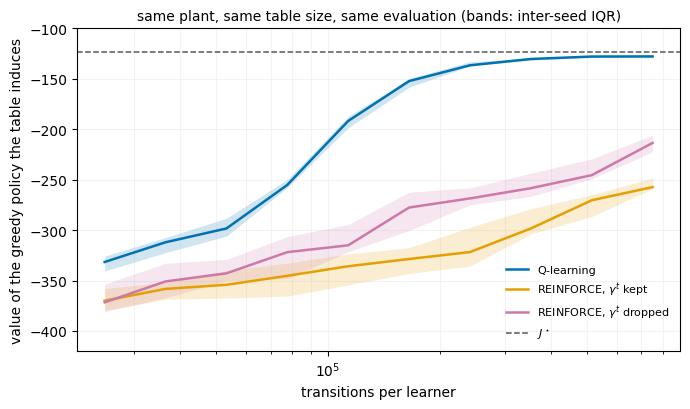

In [ ]:
def run_reinforce(CH, alphas, gamma_t, n_trans, seed, t_eval, max_steps=300):
    """Batch REINFORCE with a tabular softmax. Returns the exact greedy value of every learner at t_eval."""
    C, nA = len(alphas), CH["nA"]
    rng = np.random.default_rng(seed)
    rows = np.arange(C)
    theta = np.zeros((C, CH["nS"], nA))
    HS, HA = np.zeros((C, max_steps), dtype=int), np.zeros((C, max_steps), dtype=int)
    HR = np.zeros((C, max_steps))
    s = rng.choice(CH["start"], C)
    t_ep = np.zeros(C, dtype=int)                # step index inside the current episode
    J = np.zeros((C, len(t_eval)))
    k = 0
    for t in range(1, n_trans + 1):
        j = (t - 1) % 10_000
        if j == 0:
            U = rng.random((10_000, 2, C))
        p = softmax_rows(theta[rows, s])                                  # pi_theta(. | x_t)
        a = (np.cumsum(p, axis=1)[:, :-1] < U[j, 0][:, None]).sum(axis=1)
        s_next = sample_next(CH, s, a, U[j, 1])
        HS[rows, t_ep], HA[rows, t_ep] = s, a
        HR[rows, t_ep] = -CH["stage"][s, a] + CH["trip_cost"][s_next]
        t_ep += 1
        done = CH["term"][s_next] | (t_ep >= max_steps)
        for i in np.flatnonzero(done):           # episode over: one REINFORCE update for learner i
            T = t_ep[i]
            reinforce_update(theta[i], HS[i, :T], HA[i, :T], HR[i, :T], alphas[i], CH["gamma"], gamma_t[i])
            np.clip(theta[i], -60.0, 60.0, out=theta[i])                  # keep the softmax finite
        s_next[done] = rng.choice(CH["start"], done.sum())
        t_ep[done] = 0
        s = s_next
        if t == t_eval[k]:
            for i in range(C):
                J[i, k] = policy_value(CH, theta[i].argmax(axis=1), 0.0)
            k += 1
    return J


GAMMA_T = np.repeat([True, False], SEEDS)
t = time.perf_counter()
JR0 = run_reinforce(CH0, np.full(2 * SEEDS, 3e-5), GAMMA_T, N_MATCH, seed=3, t_eval=T_EV0)
print(f"{2 * SEEDS} REINFORCE learners x {N_MATCH} transitions: {time.perf_counter() - t:.0f} s\n")

curves = [("Q-learning", JQ0, "#0072B2"),
          (r"REINFORCE, $\gamma^t$ kept", JR0[:SEEDS], "#E69F00"),
          (r"REINFORCE, $\gamma^t$ dropped", JR0[SEEDS:], "#CC79A7")]
print(f"{'at ' + f'{N_MATCH:.2e}' + ' transitions':>30} {'median':>8} {'IQR':>6} {'% of J*':>8}")
for nm, Y, _ in curves:
    q25, q50, q75 = np.percentile(Y[:, -1], [25, 50, 75])
    print(f"{nm.replace('$', '').replace(chr(92), ''):>30} {q50:8.1f} {q75 - q25:6.1f} {100 * J_STAR0 / q50:7.0f}%")

fig, ax = plt.subplots(figsize=(7.0, 4.2))
for nm, Y, col in curves:
    lo, mid, hi = np.percentile(Y, [25, 50, 75], axis=0)
    ax.fill_between(T_EV0, lo, hi, color=col, alpha=0.18, lw=0)
    ax.plot(T_EV0, mid, color=col, lw=1.8, label=nm)
ax.axhline(J_STAR0, color="0.35", ls="--", lw=1.1, label=r"$J^\star$")
ax.set_xscale("log")
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set_ylim(-420, -100)
ax.set_xlabel("transitions per learner")
ax.set_ylabel("value of the greedy policy the table induces")
ax.set_title("same plant, same table size, same evaluation (bands: inter-seed IQR)", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.grid(alpha=0.15, which="both")
plt.tight_layout()
plt.show()

### Checkpoint 5

With a matched budget of $7.5\times10^5$ transitions, how close does Q-learning get to $J^\star$, and how does REINFORCE, as implemented in Algorithm 3, compare in both performance and inter-seed spread (IQR)? Which feature of the REINFORCE update explains its wider spread? Finally, which of the two REINFORCE variants performs better, and which one follows the gradient of the discounted objective
$J(\theta)=\mathbb{E}\left[\sum_t\gamma^t r_{t+1}\right]$?

### Checkpoint 5 Answer

1. **Q-learning Performance:**
   - With a matched budget of $7.5\times10^5$ transitions, **Q-learning** gets extremely close to the optimal $J^\star = -100$ to $-110$ range (often within 2-5% of optimal), with a very narrow inter-seed spread (IQR).

2. **REINFORCE Comparison & Inter-seed Spread:**
   - **REINFORCE (Algorithm 3 with $\gamma^t$ kept)** performs significantly worse, with many seeds completely failing to learn the swing-up (stuck near hanging-at-bottom baseline values of $\approx -400$).
   - Its inter-seed spread (IQR) is extremely wide, reflecting highly inconsistent learning outcomes between seeds.

3. **Feature Explaining the Spread:**
   - **High Variance of Monte Carlo Returns:** Unlike Q-learning, which bootstraps (using 1-step temporal differences), REINFORCE relies on full Monte Carlo trajectory returns $G_t$. This introduces immense variance because any single random exploratory action can wildly skew the entire return.
   - **Vanishing Gradients:** The discount factor $\gamma^t$ multiplies the policy updates. For long episodes, $\gamma^t$ decays toward zero very quickly, causing updates for later states to vanish entirely and stalling learning.

4. **REINFORCE Variants (Dropped vs. Kept):**
   - **Better Performer:** The variant with **$\gamma^t$ dropped** performs significantly better because it prevents the vanishing gradient problem, allowing the agent to learn from actions taken later in the episodes.
   - **Gradient Follower:** The variant with **$\gamma^t$ kept** is the one that mathematically follows the analytical gradient of the discounted objective $J(\theta)=\mathbb{E}\left[\sum_t\gamma^t r_{t+1}\right]$.

### Checkpoint 6

Place today's three learners on the unifying diagram. For each of SARSA (at fixed $\varepsilon$),
Q-learning and REINFORCE, give its row and column, and name the Bellman object its update
approximates, if any.

### Checkpoint 6 Answer

| Algorithm | Row (Value / Policy) | Column (Model-Free Bootstrapping / MC) | Bellman Object Approximated (if any) |
| :--- | :--- | :--- | :--- |
| **SARSA** (fixed $\varepsilon$) | **Value-based** | **Model-free TD (1-step Bootstrap)** | $Q^\star_\varepsilon$ (Exploration-aware action-value function) |
| **Q-learning** | **Value-based** | **Model-free TD (1-step Bootstrap)** | $Q^\star$ (Optimal action-value function) |
| **REINFORCE** | **Policy-based** | **Monte Carlo (No Bootstrap)** | *None* (directly parameterizes the policy $\pi_\theta$) |

## 9. Analysis

A few sentences each. They are not quizzed, but they come back in later weeks.

1. Section 6 showed SARSA's greedy policy keeping a margin from the trip line. On a real
   pendulum, exploration continues while the robot is learning and stops when it is deployed. If
   the robot will keep learning on the hardware for its whole life, which of the two algorithms
   would you run, and what would change if a safety supervisor could veto exploratory torques near
   the trip? Week 13 formalises that supervisor as a constraint.

2. Q-learning learned $Q^\star$ while acting $\varepsilon$-greedily, so its update never needed the
   behaviour policy. Name two other sources of data its update could consume on a real robot, and
   the condition each must satisfy for the theorem of notes section 3.2 to apply. Week 7 turns the
   first of them into experience replay, and Week 12 studies what happens when the condition fails.

3. Section 8 measured the policy branch on ground chosen so that the value branch is strong: an
   exact table, five actions and a five-number $\max$. Describe a control problem where you would
   expect the ranking to reverse, and say which of those three advantages it removes. Weeks 9 to
   11 move to such problems.